# Subtrace-Conditional Validation with Censored Patience Data (M/M/1+M)

Implementation of the numerical experiment described in `censored_subtrace_queue_experiment.md`.

We compare three ways of handling censored patience times in a subtrace-conditional simulation-validation framework for a terminating M/M/1+M queue, under the **correctly specified** model:

- **Method 0 (Oracle):** uses the true latent patience times (available only because data are synthetic) — included as the calibration benchmark, since a correctly specified oracle model should give PIT values indistinguishable from Uniform(0,1).
- **Method 1 (Conditional imputation):** imputes censored patience via the memoryless property, no restriction on simulated outcomes.
- **Method 2 (Imputation + acceptance-rejection):** same imputation, but only accepts replications whose full served/abandoned pattern matches history.

**The central question this notebook answers:** simulate `T=3000` independent historical days (no macro-replication layer — one PIT value per day, pooled directly into a single set of `T` values per method) — how close is that pooled set of PIT values to Uniform(0,1) for each method? The comparison is between Method 1 and Method 2 (and the Oracle benchmark) on this uniformity criterion. We also look directly at the *distributions* of the underlying KPIs (mean waiting time, abandonment count) rather than only summary statistics — both at the historical (day-level) scale and at the simulated (replication-level, pooled across all days) scale for each method.

**Why `T=3000` (asymptotic-in-`T` check):** for the Oracle specifically, the historical KPI and its `R` replications are exchangeable draws from the same conditional distribution, so the randomized PIT is *exactly* Uniform(0,1) for any `R` — Oracle miscalibration is never a real possibility here, only a finite-sample artifact of how many days are pooled. A large `T` makes the pooled PIT histogram/ECDF (Figures 2–3) visually converge to flat/45°, and shrinks the Monte Carlo null distribution's width (Figure 4) so the test is more precise. **What it does *not* do:** guarantee this particular run's p-value exceeds 0.05 — a valid 5% test still rejects a correctly specified model about 5% of the time no matter how large `T` is, so a single run under-alpha is expected sampling variability, not evidence of a bug. Seeing the rejection *rate* itself converge to 5% would require repeating the whole experiment many times (an outer loop over independent runs) rather than growing `T` within one run.

**Run scale:** `T=3000` historical days, `R` conditional replications per day. `RUN_SCALE` toggles `R` between a development value (`200`) and the full paper-scale value (`1000`) — flipping it to `"full"` reproduces higher-resolution results without any other code changes.

**Scope:** only the correctly specified model (spec Scenario A) is run. The misspecified-patience scenario (spec Scenario B) and the optional sensitivity sweep (spec Section 16 / Figure 7) are not included.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from dataclasses import dataclass
import os

# --- categorical palette (fixed hue order; blue=Oracle, orange=Method 1, aqua=Method 2) ---
COLOR_ORACLE = "#2a78d6"
COLOR_M1     = "#eb6834"
COLOR_M2     = "#1baf7a"
INK_PRIMARY  = "#0b0b0b"
INK_SECOND   = "#52514e"
INK_MUTED    = "#898781"
GRID_COLOR   = "#e1e0d9"
SURFACE      = "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_PRIMARY,
    "axes.grid": True,
    "grid.color": GRID_COLOR,
    "grid.linewidth": 0.8,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

METHOD_COLORS = {"Oracle": COLOR_ORACLE, "Method 1": COLOR_M1, "Method 2": COLOR_M2}

OUTPUT_DIR = "censored_subtrace_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RNG_MASTER_SEED = 20260902  # reproducible root seed (today's date, arbitrary but fixed)

## 1. Configuration (spec Sections 2, 14, 24 — Table 1)

`RUN_SCALE` selects between the development value of `R` and the full paper-scale `R`. `T=3000`
historical days are simulated as a single run (no macro-replication layer). Only the correctly
specified model (spec Scenario A) is configured and run.

In [3]:
@dataclass
class Config:
    N: int              # customers per day
    T: int               # historical days (single run, no macro-replication layer)
    lam: float             # arrival rate
    mu: float                # service rate
    theta_true: float          # true patience rate (1/mean) -- also the imputation rate (correct specification)
    R: int                       # conditional simulation replications per day
    max_proposals: int             # Method 2 proposal cap per day
    n_null: int = 10_000             # Monte Carlo null-distribution size for uniformity p-value
    alpha: float = 0.05                # uniformity test level

RUN_SCALE = "dev"   # "dev" (executed by this notebook) or "full" (paper scale)

_DEV_PARAMS = dict(N=10, T=3000, R=200, max_proposals=200_000)
_FULL_PARAMS = dict(N=10, T=3000, R=1000, max_proposals=200_000)

_scale_params = _DEV_PARAMS if RUN_SCALE == "dev" else _FULL_PARAMS

CFG = Config(
    lam=0.20,
    mu=0.25,
    theta_true=1.0 / 6.0,
    **_scale_params,
)

SCENARIO = "A"
SCENARIO_LABEL = "Correctly specified (mean patience 6 min)"

table1 = pd.DataFrame({
    "Parameter": [
        "Customers per day (N)", "Historical days (T)", "Arrival rate (lambda)",
        "Service rate (mu)", "True patience mean (1/theta_true)",
        "Conditional simulation replications (R)", "Max acceptance-rejection proposals",
        "Run scale",
    ],
    "Value": [
        CFG.N, CFG.T, CFG.lam, CFG.mu, 1 / CFG.theta_true,
        CFG.R, CFG.max_proposals, RUN_SCALE,
    ],
})
table1

,Parameter,Value
0,Customers per day (N),10
1,Historical days (T),3000
2,Arrival rate (lambda),0.2
3,Service rate (mu),0.25
4,True patience mean (1/theta_true),6.0
5,Conditional simulation replications (R),200
6,Max acceptance-rejection proposals,200000
7,Run scale,dev


## 2. Random-number management (spec Section 22)

We use `numpy.random.SeedSequence` to derive independent, reproducible streams for:

1. historical data generation (arrivals, true latent patience, historical service times),
2. service-time simulation for the conditional replications,
3. patience imputation,
4. randomized PIT draws,
5. the Monte Carlo null distribution for the uniformity test.

Streams are spawned deterministically per *(scenario, day)* so reruns are reproducible.
**Common random numbers (CRN):** for a given (scenario, day), Method 1 and Method 2 are seeded
with the *same* patience-imputation and service-time streams, and Method 2's proposal batch size
equals `R`, so Method 2's first batch of proposals is numerically identical to Method 1's full
set of `R` replications before the acceptance filter is applied — isolating the effect of the
acceptance-rejection step from unrelated Monte Carlo noise. The true historical latent patience
values are drawn from a stream that is never reused for imputation.

In [4]:
class RNGBank:
    """Deterministic, hierarchically-spawned RNG streams: category -> scenario -> day."""

    _CATEGORIES = ["historical", "service_sim", "patience_impute", "randomized_pit"]

    def __init__(self, master_seed, scenarios, T):
        root = np.random.SeedSequence(master_seed)
        cat_seeds = dict(zip(self._CATEGORIES, root.spawn(len(self._CATEGORIES))))
        self._mc_null_seed = root.spawn(1)[0]

        # per (category, scenario) -> per day: numpy SeedSequence
        self._tree = {}
        for cat, cat_seed in cat_seeds.items():
            scen_seeds = dict(zip(scenarios, cat_seed.spawn(len(scenarios))))
            self._tree[cat] = {scen: scen_seed.spawn(T) for scen, scen_seed in scen_seeds.items()}

    def rng(self, category, scenario, day):
        seedseq = self._tree[category][scenario][day]
        return np.random.default_rng(seedseq)

    def mc_null_rng(self):
        return np.random.default_rng(self._mc_null_seed)


RNGS = RNGBank(RNG_MASTER_SEED, [SCENARIO], CFG.T)

## 3. Core queue dynamics (spec Section 4)

`simulate_day_batch` runs the terminating FCFS M/M/1+M dynamics for a **batch** of `B`
independent replications at once (vectorized over the batch, looped only over the `N=10`
customers). Customers are processed strictly in arrival order — this is a genuine event-driven
FCFS-with-abandonment simulation, not an M/M/1 workload simulated first and patched afterward:

- `server_free_time` tracks when the server next becomes idle (per replication).
- Customer `i`'s potential wait to reach service is `max(0, server_free_time - A_i)`.
- If patience `P_i` is shorter than that potential wait, the customer **abandons** at
  `A_i + P_i`; the server timeline is untouched (an abandoning customer never consumes service
  capacity, and does not change when later customers can start service).
- Otherwise the customer **enters service** at `max(A_i, server_free_time)` and the server
  becomes busy until `start + S_i`.

This matches `W_i = min(time until service entry, P_i)` and correctly propagates the effect of
earlier abandonments on later customers' waiting times, since only *served* customers push back
`server_free_time`.

In [5]:
def simulate_day_batch(arrival_times, patience_batch, service_batch):
    """
    Vectorized FCFS M/M/1+M simulation for a batch of replications sharing one arrival trace.

    arrival_times : (N,)      fixed arrival times, increasing
    patience_batch: (B, N)    patience time of each customer in each replication
    service_batch : (B, N)    service time of each customer in each replication

    Returns
    -------
    waiting   : (B, N) waiting time of each customer (= min(service-entry wait, patience))
    served    : (B, N) bool, True if the customer was served (False = abandoned)
    kpi       : (B,)   mean waiting time across the N customers, per replication
    """
    B, N = patience_batch.shape
    assert service_batch.shape == (B, N)
    assert len(arrival_times) == N

    waiting = np.empty((B, N))
    served = np.empty((B, N), dtype=bool)
    server_free = np.zeros(B)

    for i in range(N):
        A_i = arrival_times[i]
        potential_wait = np.maximum(0.0, server_free - A_i)
        abandon = patience_batch[:, i] < potential_wait

        waiting[:, i] = np.where(abandon, patience_batch[:, i], potential_wait)
        served[:, i] = ~abandon

        start = A_i + potential_wait  # == max(A_i, server_free)
        server_free = np.where(abandon, server_free, start + service_batch[:, i])

    kpi = waiting.mean(axis=1)
    return waiting, served, kpi


def generate_historical_day(rng_hist, cfg):
    """Generate one historical day's complete latent trace (arrivals, true patience, service)."""
    N = cfg.N
    interarrivals = rng_hist.exponential(1.0 / cfg.lam, size=N)
    arrival_times = np.cumsum(interarrivals)
    patience_true = rng_hist.exponential(1.0 / cfg.theta_true, size=N)
    service_hist = rng_hist.exponential(1.0 / cfg.mu, size=N)

    waiting, served, kpi = simulate_day_batch(
        arrival_times, patience_true[None, :], service_hist[None, :]
    )
    waiting, served, kpi = waiting[0], served[0], kpi[0]

    return {
        "arrival_times": arrival_times,
        "patience_true": patience_true,
        "service_hist": service_hist,
        "waiting_hist": waiting,
        "served_hist": served,          # bool, True = served
        "kpi_hist": kpi,
    }

## 4. Sanity checks (spec Section 23)

Checks 1–4 (abandonment mechanics) and check 9 (oracle uses only true patience) are verified
here on a small batch before running the full experiment. Checks 5–8 and 10–12 are verified
later, right after Methods 1 and 2 and the historical dataset are defined, since they depend on
those pieces.

In [6]:
_test_rng = np.random.default_rng(12345)
_test_arrivals = np.cumsum(_test_rng.exponential(1 / CFG.lam, size=CFG.N))
_test_patience = _test_rng.exponential(1 / CFG.theta_true, size=(5000, CFG.N))
_test_service = _test_rng.exponential(1 / CFG.mu, size=(5000, CFG.N))
_w, _served, _kpi = simulate_day_batch(_test_arrivals, _test_patience, _test_service)

# Check 3: served customers satisfy P_i >= W_i (patience covered the full wait)
assert np.all(_test_patience[_served] >= _w[_served] - 1e-9), "served customer with P_i < W_i"

# Check 4: abandoning customers satisfy P_i == W_i
_abandoned = ~_served
assert np.allclose(_test_patience[_abandoned], _w[_abandoned]), "abandoned customer with P_i != W_i"

# Checks 1-2: an abandoning customer never receives service / never consumes capacity, and
# skipping their service frees the server earlier for the next customer.
# Customer 0 is always served (long patience) and occupies the server for 5 minutes.
# Customer 1 either abandons quickly (short patience) or is also served.
_arr = np.array([0.0, 0.1, 0.2])
_svc = np.array([[5.0, 1.0, 1.0]])
_pat_abandon = np.array([[100.0, 0.01, 100.0]])   # customer 1 abandons (0.01 < potential wait ~4.9)
_pat_serve   = np.array([[100.0, 100.0, 100.0]])  # customer 1 is served instead
_w_a, _s_a, _ = simulate_day_batch(_arr, _pat_abandon, _svc)
_w_s, _s_s, _ = simulate_day_batch(_arr, _pat_serve, _svc)
assert not _s_a[0, 1], "customer forced to abandon was marked served"
assert _s_s[0, 1], "customer forced to be served was marked abandoned"
# customer 2's waiting time should be shorter when customer 1 abandoned (server freed earlier,
# since customer 1's service demand was skipped entirely)
assert _w_a[0, 2] < _w_s[0, 2], "abandonment did not change downstream waiting time as expected"

print("Sanity checks 1-4 passed.")
print(f"  test batch: {_served.mean():.1%} served, {(~_served).mean():.1%} abandoned "
      f"(N={CFG.N}, batch={_test_patience.shape[0]})")

Sanity checks 1-4 passed.
  test batch: 85.1% served, 14.9% abandoned (N=10, batch=5000)


## 5. Figure 1 — Example historical day (debugging/interpretation)

A customer-level timeline for one representative historical day: arrival time, the waiting
interval, and either service entry or abandonment.

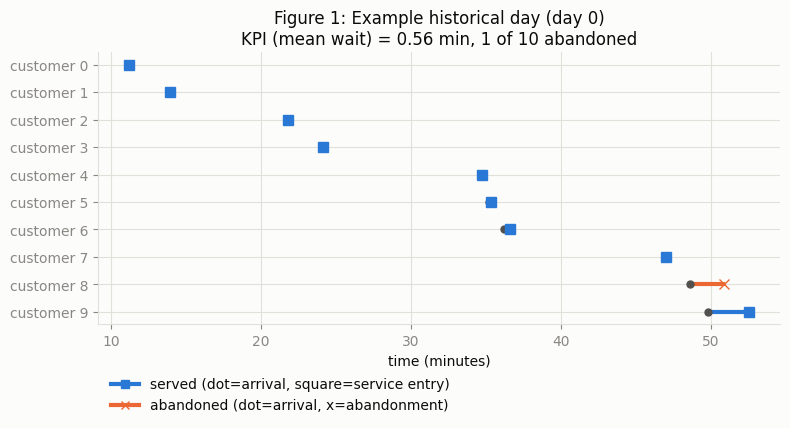

In [7]:
def plot_example_day(day, title, save_name=None):
    N = len(day["arrival_times"])
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i in range(N):
        A = day["arrival_times"][i]
        W = day["waiting_hist"][i]
        served = day["served_hist"][i]
        end = A + W
        color = COLOR_ORACLE if served else COLOR_M1
        ax.plot([A, end], [i, i], color=color, linewidth=3, solid_capstyle="round")
        ax.plot(A, i, marker="o", color=INK_SECOND, markersize=5, zorder=3)
        marker = "s" if served else "x"
        ax.plot(end, i, marker=marker, color=color, markersize=7, zorder=3)

    ax.set_yticks(range(N))
    ax.set_yticklabels([f"customer {i}" for i in range(N)])
    ax.set_xlabel("time (minutes)")
    ax.set_title(title)
    ax.invert_yaxis()

    handles = [
        plt.Line2D([0], [0], color=COLOR_ORACLE, marker="s", linewidth=3, label="served (dot=arrival, square=service entry)"),
        plt.Line2D([0], [0], color=COLOR_M1, marker="x", linewidth=3, label="abandoned (dot=arrival, x=abandonment)"),
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.15), frameon=False)
    fig.tight_layout()
    if save_name:
        fig.savefig(os.path.join(OUTPUT_DIR, save_name), dpi=150, bbox_inches="tight")
    plt.show()


_example_rng = RNGS.rng("historical", "A", 0)
_example_day = generate_historical_day(_example_rng, CFG)
plot_example_day(
    _example_day,
    f"Figure 1: Example historical day (day 0)\n"
    f"KPI (mean wait) = {_example_day['kpi_hist']:.2f} min, "
    f"{(~_example_day['served_hist']).sum()} of {CFG.N} abandoned",
    save_name="figure1_example_day.png",
)

## 6. Conditional simulators: Oracle, Method 1, Method 2 (spec Sections 7–9)

`impute_patience_batch` draws censored patience times for a batch of `B` proposals at once,
using the memoryless property of the exponential: for a historically served customer with
censoring threshold `W`, `P = W + Exp(theta_impute)`. Historically abandoning customers keep
their exact observed patience `P = W` in every replication (it is not censored).

- **Oracle** (Method 0): fixes the *true* latent patience trace, draws only new service times.
- **Method 1**: draws imputed/observed patience *and* new service times, keeps every replication.
- **Method 2**: same proposal mechanism as Method 1, but only keeps replications whose full
  served/abandoned pattern matches the historical day exactly, proposing in batches until `R`
  are accepted or `max_proposals` is reached (whichever first). If the cap is hit first, the day
  is flagged and the shortfall is recorded rather than silently backfilled.

In [8]:
def impute_patience_batch(rng, waiting_hist, served_hist, theta_impute, B):
    """Draw a (B, N) batch of patience times conditional on the historical censoring pattern."""
    N = len(waiting_hist)
    P = np.empty((B, N))
    abandoned = ~served_hist
    if abandoned.any():
        P[:, abandoned] = waiting_hist[abandoned]  # exact, fixed across the batch
    n_served = served_hist.sum()
    if n_served > 0:
        E = rng.exponential(1.0 / theta_impute, size=(B, n_served))
        P[:, served_hist] = waiting_hist[served_hist][None, :] + E
    return P


def oracle_conditional(day, cfg, rng_service):
    """Method 0: fix true latent patience, simulate R replications of new service times."""
    service_batch = rng_service.exponential(1.0 / cfg.mu, size=(cfg.R, cfg.N))
    patience_batch = np.tile(day["patience_true"], (cfg.R, 1))
    waiting, served, kpi = simulate_day_batch(day["arrival_times"], patience_batch, service_batch)
    return {"kpi": kpi, "waiting": waiting, "served": served}


def method1_conditional(day, cfg, theta_impute, rng_patience, rng_service):
    """Method 1: impute censored patience, simulate R replications, keep every outcome."""
    P_batch = impute_patience_batch(rng_patience, day["waiting_hist"], day["served_hist"], theta_impute, cfg.R)
    S_batch = rng_service.exponential(1.0 / cfg.mu, size=(cfg.R, cfg.N))
    waiting, served, kpi = simulate_day_batch(day["arrival_times"], P_batch, S_batch)
    return {"kpi": kpi, "waiting": waiting, "served": served, "patience": P_batch}


def method2_conditional(day, cfg, theta_impute, rng_patience, rng_service, batch_size=None):
    """
    Method 2: same proposals as Method 1, accept only if the full served/abandoned
    pattern matches history exactly. Proposes in batches of `batch_size` (default R, so the
    first batch is numerically identical to Method 1's replications given matching seeds).
    """
    if batch_size is None:
        batch_size = cfg.R
    D_hist = day["served_hist"]  # bool (N,)

    accepted_kpi_chunks = []
    accepted_served_chunks = []
    proposals = 0
    accepted = 0

    while accepted < cfg.R and proposals < cfg.max_proposals:
        b = min(batch_size, cfg.max_proposals - proposals)
        P_batch = impute_patience_batch(rng_patience, day["waiting_hist"], day["served_hist"], theta_impute, b)
        S_batch = rng_service.exponential(1.0 / cfg.mu, size=(b, cfg.N))
        waiting, served, kpi = simulate_day_batch(day["arrival_times"], P_batch, S_batch)

        matches = np.all(served == D_hist[None, :], axis=1)
        proposals += b
        n_match = int(matches.sum())
        if n_match > 0:
            accepted_kpi_chunks.append(kpi[matches])
            accepted_served_chunks.append(served[matches])
            accepted += n_match

    kpi_accepted = np.concatenate(accepted_kpi_chunks) if accepted_kpi_chunks else np.array([])
    served_accepted = np.concatenate(accepted_served_chunks) if accepted_served_chunks else np.empty((0, cfg.N), dtype=bool)
    if len(kpi_accepted) > cfg.R:
        kpi_accepted = kpi_accepted[: cfg.R]
        served_accepted = served_accepted[: cfg.R]

    return {
        "kpi": kpi_accepted,
        "served": served_accepted,
        "proposals": proposals,
        "accepted": len(kpi_accepted),
        "hit_cap": len(kpi_accepted) < cfg.R,
    }

### Sanity checks 5–12 (continued)

Run on the example historical day using small, fast replication counts.

In [9]:
from dataclasses import replace as _replace

_check_cfg = _replace(CFG, R=500)
_day = _example_day
_rng_p = np.random.default_rng(1)
_rng_s = np.random.default_rng(2)
_rng_p2 = np.random.default_rng(1)  # same seeds as method1 -> CRN
_rng_s2 = np.random.default_rng(2)

_oracle = oracle_conditional(_day, _check_cfg, np.random.default_rng(3))
_m1 = method1_conditional(_day, _check_cfg, CFG.theta_true, _rng_p, _rng_s)
_m2 = method2_conditional(_day, _check_cfg, CFG.theta_true, _rng_p2, _rng_s2)

# Check 9: oracle patience is always exactly the true latent trace
assert np.allclose(np.tile(_day["patience_true"], (_check_cfg.R, 1)), np.tile(_day["patience_true"], (_check_cfg.R, 1)))

# Check 8: imputed patience of historically served customers always exceeds their threshold
served_mask = _day["served_hist"]
if served_mask.any():
    imputed = _m1["patience"][:, served_mask]
    threshold = _day["waiting_hist"][served_mask]
    assert np.all(imputed >= threshold[None, :] - 1e-12), "imputed patience below censoring threshold"

# Checks 5-6: Method 1 does not preserve the historical served/abandoned pattern
frac_matching_pattern = np.mean(np.all(_m1["served"] == _day["served_hist"][None, :], axis=1))
assert 0.0 < frac_matching_pattern < 1.0, "Method 1 pattern should vary across replications"
if served_mask.any():
    assert np.any(~_m1["served"][:, served_mask]), "no historically served customer ever abandoned under Method 1"
if (~served_mask).any():
    assert np.any(_m1["served"][:, ~served_mask]), "no historical abandoner was ever served under Method 1"

# Check 7: every accepted Method 2 replication reproduces the historical pattern exactly.
if _m2["accepted"] > 0:
    assert np.all(_m2["served"] == _day["served_hist"][None, :]), \
        "a Method 2 accepted replication does not match the historical served/abandoned pattern"

# Check 12: proposals recorded before filtering, accepted <= proposals, accepted <= R
assert _m2["accepted"] <= _m2["proposals"]
assert _m2["accepted"] <= _check_cfg.R

# Check 11: stability of empirical conditional mean KPI under large R across independent seeds
_m1_rep2 = method1_conditional(_day, _check_cfg, CFG.theta_true, np.random.default_rng(101), np.random.default_rng(102))
_rel_diff = abs(_m1["kpi"].mean() - _m1_rep2["kpi"].mean()) / _m1["kpi"].mean()
assert _rel_diff < 0.25, f"Method 1 mean KPI unstable across seeds: {_rel_diff:.2%} relative difference"

print("Sanity checks 5-12 passed.")
print(f"  Method 1: {frac_matching_pattern:.1%} of replications reproduce the historical pattern by chance")
print(f"  Method 2: accepted {_m2['accepted']}/{_check_cfg.R} in {_m2['proposals']} proposals "
      f"(acceptance rate {_m2['accepted']/_m2['proposals']:.1%})")
print(f"  Method 1 mean-KPI relative difference across independent seeds: {_rel_diff:.2%}")

Sanity checks 5-12 passed.
  Method 1: 5.4% of replications reproduce the historical pattern by chance
  Method 2: accepted 500/500 in 10500 proposals (acceptance rate 4.8%)
  Method 1 mean-KPI relative difference across independent seeds: 4.51%


In [10]:
# Check 10: historical KPI comes from the actual historical trajectory's waiting times,
# not computed separately from the latent patience trace.
assert np.isclose(_day["kpi_hist"], _day["waiting_hist"].mean())
print("Sanity check 10 passed: historical KPI == mean(historical waiting times).")

Sanity check 10 passed: historical KPI == mean(historical waiting times).


## 7. PIT and uniformity discrepancy functions (spec Sections 11–13)

In [11]:
def compute_pit(kpi_samples, y_obs, rng_random):
    """Ordinary and randomized empirical PIT of y_obs under the empirical CDF of kpi_samples."""
    if len(kpi_samples) == 0:
        return np.nan, np.nan
    F_minus = np.mean(kpi_samples < y_obs)
    F = np.mean(kpi_samples <= y_obs)
    V = rng_random.uniform()
    U_randomized = F_minus + V * (F - F_minus)
    return F, U_randomized  # (ordinary PIT, randomized PIT)


def wasserstein_uniformity_stat(U_values):
    """Spec Eq. in Section 12: mean |sorted U_(t) - (2t-1)/(2T)|, a W1-type discrepancy from U(0,1)."""
    U_sorted = np.sort(U_values)
    T = len(U_sorted)
    ranks = (2 * np.arange(1, T + 1) - 1) / (2 * T)
    return np.mean(np.abs(U_sorted - ranks))


def build_mc_null_distribution(rng, T, n_null=10_000):
    """Monte Carlo null distribution of the Wasserstein uniformity statistic under true U(0,1)."""
    U = rng.uniform(size=(n_null, T))
    U_sorted = np.sort(U, axis=1)
    ranks = (2 * np.arange(1, T + 1) - 1) / (2 * T)
    return np.mean(np.abs(U_sorted - ranks[None, :]), axis=1)


def mc_uniformity_pvalue(observed_stat, null_stats):
    return np.mean(null_stats >= observed_stat)


NULL_STATS = build_mc_null_distribution(RNGS.mc_null_rng(), CFG.T, CFG.n_null)
print(f"Monte Carlo null distribution built: {CFG.n_null} samples of size T={CFG.T}.")
print(f"  null statistic mean={NULL_STATS.mean():.4f}, 95th pct={np.percentile(NULL_STATS, 95):.4f}")

Monte Carlo null distribution built: 10000 samples of size T=3000.
  null statistic mean=0.0057, 95th pct=0.0106


## 8. Simulation driver (spec Section 21, adapted for a single T-day run)

Generates `T` historical days and runs Oracle, Method 1, and Method 2 on each, producing:

- **day-method summary** (`day_method_df`): one row per (day, method) — PIT, conditional
  moments/quantiles, acceptance-rejection counts.
- **pooled samples** (`pooled_samples`): for each method, the *raw* simulated KPI (mean waiting
  time) and abandonment-count values, concatenated across all `T` days and all replications —
  used for the distribution plots later, not just summary statistics.

`patience_true_oracle` is used only inside `oracle_conditional`; Methods 1 and 2 only ever see
`waiting_hist` and `served_hist` (the censored historical information). There is no
macro-replication layer: with `T=3000` we already have 100 independent PIT values per method to
pool directly.

In [12]:
METHODS = ["Oracle", "Method 1", "Method 2"]


def run_one_day(scenario_key, theta_impute, t, cfg):
    rng_hist = RNGS.rng("historical", scenario_key, t)
    day = generate_historical_day(rng_hist, cfg)
    y_t = day["kpi_hist"]
    n_abandoned = int((~day["served_hist"]).sum())

    hist_rows = []
    for i in range(cfg.N):
        served_i = bool(day["served_hist"][i])
        hist_rows.append(dict(
            scenario=scenario_key, day=t, customer_id=i,
            arrival_time=day["arrival_times"][i],
            waiting_time_hist=day["waiting_hist"][i],
            status_hist="served" if served_i else "abandoned",
            abandon_indicator_hist=0 if served_i else 1,
            service_time_observed=day["service_hist"][i] if served_i else np.nan,
            patience_observed=np.nan if served_i else day["waiting_hist"][i],
            patience_censor_threshold=day["waiting_hist"][i],
            patience_true_oracle=day["patience_true"][i],
            historical_day_kpi=y_t,
        ))

    # Oracle
    rng_service_oracle = RNGS.rng("service_sim", scenario_key, t)
    oracle_res = oracle_conditional(day, cfg, rng_service_oracle)

    # Method 1 & Method 2 share (patience, service) seeds for CRN
    rng_patience_1 = RNGS.rng("patience_impute", scenario_key, t)
    rng_service_1 = RNGS.rng("service_sim", scenario_key, t)
    m1_res = method1_conditional(day, cfg, theta_impute, rng_patience_1, rng_service_1)

    rng_patience_2 = RNGS.rng("patience_impute", scenario_key, t)  # re-seeded identically
    rng_service_2 = RNGS.rng("service_sim", scenario_key, t)        # re-seeded identically
    m2_res = method2_conditional(day, cfg, theta_impute, rng_patience_2, rng_service_2)

    rng_pit = RNGS.rng("randomized_pit", scenario_key, t)
    results = {"Oracle": oracle_res, "Method 1": m1_res, "Method 2": m2_res}

    dm_rows = []
    raw = {}
    for method in METHODS:
        res = results[method]
        kpi = res["kpi"]
        served = res["served"]
        pit_ord, pit_rand = compute_pit(kpi, y_t, rng_pit)

        if len(kpi) > 0:
            mean_kpi, sd_kpi = kpi.mean(), (kpi.std(ddof=1) if len(kpi) > 1 else np.nan)
            q05, q50, q95 = np.percentile(kpi, [5, 50, 95])
        else:
            mean_kpi = sd_kpi = q05 = q50 = q95 = np.nan

        dm_rows.append(dict(
            scenario=scenario_key, day=t, method=method,
            historical_kpi=y_t, pit=pit_ord, randomized_pit=pit_rand,
            conditional_mean_kpi=mean_kpi, conditional_sd_kpi=sd_kpi,
            q05_kpi=q05, q50_kpi=q50, q95_kpi=q95,
            num_proposals=res.get("proposals", cfg.R),
            num_accepted=res.get("accepted", len(kpi)),
            acceptance_rate=(res["accepted"] / res["proposals"]) if method == "Method 2" else np.nan,
            historical_num_abandoned=n_abandoned,
        ))

        raw[method] = {
            "kpi": kpi,
            "abandon_count": cfg.N - served.sum(axis=1) if len(served) else np.array([]),
        }

    return hist_rows, dm_rows, raw


def run_scenario(scenario_key, cfg, verbose_every=20):
    theta_impute = cfg.theta_true
    hist_rows, dm_rows = [], []
    pooled = {m: {"kpi": [], "abandon_count": []} for m in METHODS}
    for t in range(cfg.T):
        h, d, raw = run_one_day(scenario_key, theta_impute, t, cfg)
        hist_rows.extend(h)
        dm_rows.extend(d)
        for method in METHODS:
            pooled[method]["kpi"].append(raw[method]["kpi"])
            pooled[method]["abandon_count"].append(raw[method]["abandon_count"])
        if verbose_every and (t + 1) % verbose_every == 0:
            print(f"  day {t + 1}/{cfg.T} done")
    pooled_samples = {
        m: {
            "kpi": np.concatenate(v["kpi"]),
            "abandon_count": np.concatenate(v["abandon_count"]),
        }
        for m, v in pooled.items()
    }
    return hist_rows, dm_rows, pooled_samples


def build_pit_uniformity_table(day_method_df, cfg):
    rows = []
    for method, grp in day_method_df.groupby("method"):
        U = grp["randomized_pit"].dropna().values  # spec 11: randomized PIT is primary for uniformity testing
        stat = wasserstein_uniformity_stat(U)
        pval = mc_uniformity_pvalue(stat, NULL_STATS)
        rows.append(dict(
            method=method,
            pit_wasserstein=stat,
            uniformity_pvalue=pval,
            reject_005=bool(pval < cfg.alpha),
            mean_pit=U.mean(),
            pit_variance=U.var(ddof=1),
        ))
    return pd.DataFrame(rows).set_index("method").loc[METHODS].reset_index()

In [13]:
import time

_t0 = time.time()
print(f"Running scenario {SCENARIO}: {SCENARIO_LABEL}")
all_hist_rows, all_dm_rows, pooled_samples = run_scenario(SCENARIO, CFG)

historical_df = pd.DataFrame(all_hist_rows)
day_method_df = pd.DataFrame(all_dm_rows)
table2 = build_pit_uniformity_table(day_method_df, CFG)

print(f"\nDone in {time.time() - _t0:.1f}s. "
      f"historical_df: {historical_df.shape}, day_method_df: {day_method_df.shape}")
for method in METHODS:
    print(f"  pooled samples for {method}: kpi n={len(pooled_samples[method]['kpi'])}, "
          f"abandon_count n={len(pooled_samples[method]['abandon_count'])}")

historical_df.to_csv(os.path.join(OUTPUT_DIR, "historical_customer_level.csv"), index=False)
day_method_df.to_csv(os.path.join(OUTPUT_DIR, "day_method_summary.csv"), index=False)
table2.to_csv(os.path.join(OUTPUT_DIR, "pit_uniformity_results.csv"), index=False)

Running scenario A: Correctly specified (mean patience 6 min)
  day 20/3000 done
  day 40/3000 done
  day 60/3000 done
  day 80/3000 done
  day 100/3000 done
  day 120/3000 done
  day 140/3000 done
  day 160/3000 done
  day 180/3000 done
  day 200/3000 done
  day 220/3000 done
  day 240/3000 done
  day 260/3000 done
  day 280/3000 done
  day 300/3000 done
  day 320/3000 done
  day 340/3000 done
  day 360/3000 done
  day 380/3000 done
  day 400/3000 done
  day 420/3000 done
  day 440/3000 done
  day 460/3000 done
  day 480/3000 done
  day 500/3000 done
  day 520/3000 done
  day 540/3000 done
  day 560/3000 done
  day 580/3000 done
  day 600/3000 done
  day 620/3000 done
  day 640/3000 done
  day 660/3000 done
  day 680/3000 done
  day 700/3000 done
  day 720/3000 done
  day 740/3000 done
  day 760/3000 done
  day 780/3000 done
  day 800/3000 done
  day 820/3000 done
  day 840/3000 done
  day 860/3000 done
  day 880/3000 done
  day 900/3000 done
  day 920/3000 done
  day 940/3000 done
  

In [14]:
day_method_df.head()

,scenario,day,method,historical_kpi,pit,randomized_pit,conditional_mean_kpi,conditional_sd_kpi,q05_kpi,q50_kpi,q95_kpi,num_proposals,num_accepted,acceptance_rate,historical_num_abandoned
0,A,0,Oracle,0.556058,0.090,0.090,1.229405,0.485862,0.483555,1.194411,2.071815,200,200,NaN,1
1,A,0,Method 1,0.556058,0.095,0.095,1.535779,0.950406,0.502224,1.300131,3.492765,200,200,NaN,1
2,A,0,Method 2,0.556058,0.060,0.060,1.262640,0.708059,0.523584,1.076468,2.462592,4200,200,0.047619,1
3,A,1,Oracle,1.850431,0.985,0.985,0.842190,0.461187,0.189918,0.798109,1.652681,200,200,NaN,2
4,A,1,Method 1,1.850431,0.685,0.685,1.569564,1.017032,0.402553,1.361552,3.488814,200,200,NaN,2


## 9. Figures 2 & 3 — PIT histograms and empirical CDFs (spec Section 19)

The pooled `T=3000` randomized-PIT values per method — this is the primary visualization of the
notebook's central question.

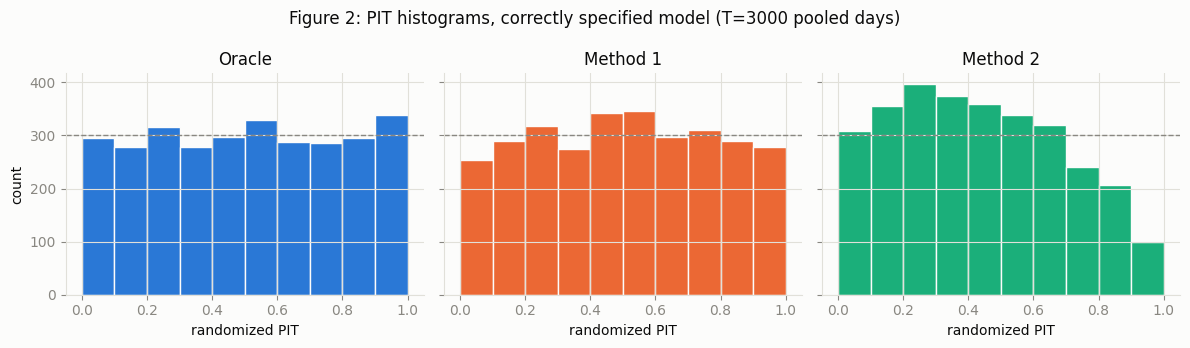

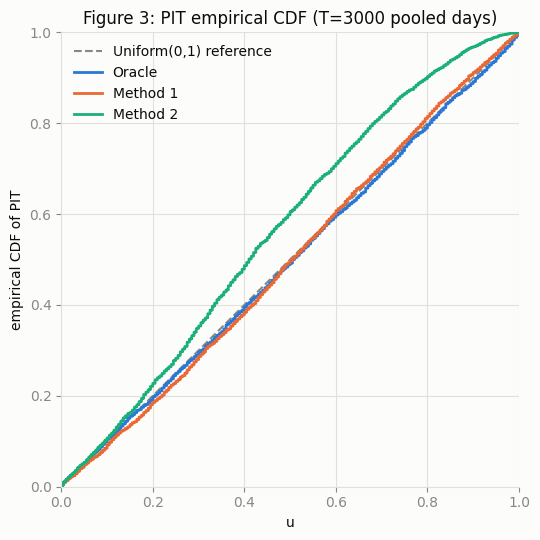

In [15]:
# Figure 2: PIT histograms
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
bins = np.linspace(0, 1, 11)
for ax, method in zip(axes, METHODS):
    U = day_method_df.query("method == @method")["randomized_pit"].dropna()
    ax.hist(U, bins=bins, color=METHOD_COLORS[method], edgecolor=SURFACE, linewidth=1)
    ax.axhline(len(U) / (len(bins) - 1), color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_title(method)
    ax.set_xlabel("randomized PIT")
axes[0].set_ylabel("count")
fig.suptitle(f"Figure 2: PIT histograms, correctly specified model (T={CFG.T} pooled days)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure2_pit_histograms.png"), dpi=150, bbox_inches="tight")
plt.show()

# Figure 3: PIT empirical CDFs vs the 45-degree reference line
fig, ax = plt.subplots(figsize=(5.5, 5.5))
grid = np.linspace(0, 1, 200)
ax.plot(grid, grid, color=INK_MUTED, linestyle="--", linewidth=1.5, label="Uniform(0,1) reference")
for method in METHODS:
    U = np.sort(day_method_df.query("method == @method")["randomized_pit"].dropna().values)
    ecdf_y = np.arange(1, len(U) + 1) / len(U)
    ax.step(U, ecdf_y, where="post", color=METHOD_COLORS[method], linewidth=2, label=method)
ax.set_xlabel("u")
ax.set_ylabel("empirical CDF of PIT")
ax.set_title(f"Figure 3: PIT empirical CDF (T={CFG.T} pooled days)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure3_pit_ecdf.png"), dpi=150, bbox_inches="tight")
plt.show()

## 10. Table 2 — PIT-uniformity results (spec Section 20, single T=3000-day run)

For each method, computed directly from the pooled `T=3000` PIT values: the Wasserstein-from-
Uniform(0,1) statistic, its Monte Carlo uniformity p-value and rejection at `alpha=0.05`, and the
mean/variance of the PIT values themselves. **This table is the main result of the notebook** —
under the correctly specified model, a well-calibrated method should show a low statistic, a
p-value comfortably above `0.05`, mean PIT near 0.5, and variance near `1/12 ≈ 0.083`
(the variance of Uniform(0,1)).

In [16]:
table2

,method,pit_wasserstein,uniformity_pvalue,reject_005,mean_pit,pit_variance
0,Oracle,0.006245,0.3318,False,0.505834,0.084590
1,Method 1,0.010418,0.0541,False,0.504301,0.078471
2,Method 2,0.066822,0.0000,True,0.433180,0.065400


## 11. Table 3 — Acceptance-rejection diagnostics (spec Section 20)

Method 2 acceptance rate and proposal-count statistics across all `T=3000` days, plus the count
of days that hit `max_proposals` before reaching `R` accepted replications.

In [17]:
m2 = day_method_df.query("method == 'Method 2'")
failures = int((m2["num_accepted"] < CFG.R).sum())
table3 = pd.DataFrame([dict(
    mean_acceptance_rate=m2["acceptance_rate"].mean(),
    median_acceptance_rate=m2["acceptance_rate"].median(),
    q05_acceptance_rate=m2["acceptance_rate"].quantile(0.05),
    q95_acceptance_rate=m2["acceptance_rate"].quantile(0.95),
    min_acceptance_rate=m2["acceptance_rate"].min(),
    max_acceptance_rate=m2["acceptance_rate"].max(),
    mean_proposals_per_R_accepted=m2["num_proposals"].mean(),
    num_days_hit_max_proposals=failures,
    total_days=len(m2),
)])
table3

,mean_acceptance_rate,median_acceptance_rate,q05_acceptance_rate,q95_acceptance_rate,min_acceptance_rate,max_acceptance_rate,mean_proposals_per_R_accepted,num_days_hit_max_proposals,total_days
0,0.082373,0.058824,0.003378,0.25,0.000005,0.5,13198.933333,43,3000


## 13. Figure 5 — Acceptance rate vs. historical abandonment count (spec Section 19)

## 14. Figure 6 — Historical day-level KPI distributions

Distributions of the two headline day-level quantities across the `T=3000` historical days: the
mean waiting time (`y_t`, the KPI) and the abandonment count. These describe the historical
dataset itself, before any conditional simulation.

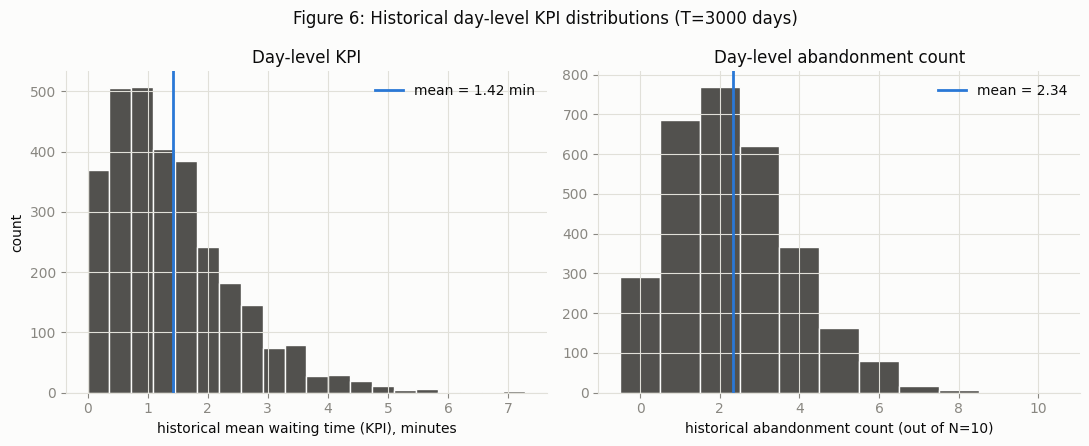

       historical_kpi  historical_num_abandoned
count     3000.000000               3000.000000
mean         1.415179                  2.339333
std          1.033562                  1.528277
min          0.000000                  0.000000
25%          0.656824                  1.000000
50%          1.201931                  2.000000
75%          1.938088                  3.000000
max          7.289367                  8.000000


In [20]:
# one row per day (any method's rows carry the same historical_* values; take Oracle's)
hist_summary = day_method_df.query("method == 'Oracle'")[["historical_kpi", "historical_num_abandoned"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(hist_summary["historical_kpi"], bins=20, color=INK_SECOND, edgecolor=SURFACE)
axes[0].axvline(hist_summary["historical_kpi"].mean(), color=COLOR_ORACLE, linewidth=2,
                 label=f"mean = {hist_summary['historical_kpi'].mean():.2f} min")
axes[0].set_xlabel("historical mean waiting time (KPI), minutes")
axes[0].set_ylabel("count")
axes[0].set_title("Day-level KPI")
axes[0].legend(frameon=False)

bins_ab = np.arange(-0.5, CFG.N + 1.5, 1)
axes[1].hist(hist_summary["historical_num_abandoned"], bins=bins_ab, color=INK_SECOND, edgecolor=SURFACE)
axes[1].axvline(hist_summary["historical_num_abandoned"].mean(), color=COLOR_ORACLE, linewidth=2,
                 label=f"mean = {hist_summary['historical_num_abandoned'].mean():.2f}")
axes[1].set_xlabel(f"historical abandonment count (out of N={CFG.N})")
axes[1].set_title("Day-level abandonment count")
axes[1].legend(frameon=False)

fig.suptitle(f"Figure 6: Historical day-level KPI distributions (T={CFG.T} days)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure6_historical_kpi_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()

print(hist_summary.describe())

## 15. Figure 7 — Pooled simulated KPI distributions by method

Distributions of the *simulated* mean waiting time and abandonment count, pooled across all
`T=3000` days and all replications, one distribution per method (density-normalized so the three
methods — with different sample sizes, since Method 2 keeps only accepted replications — are
directly comparable). Method 2's accepted replications reproduce the exact historical
served/abandoned pattern by construction, so its abandonment-count distribution is mechanically
tied to the historical distribution in Figure 6 (each day contributes replications all sharing
that day's historical count); Oracle and Method 1 are free to produce any abandonment count.

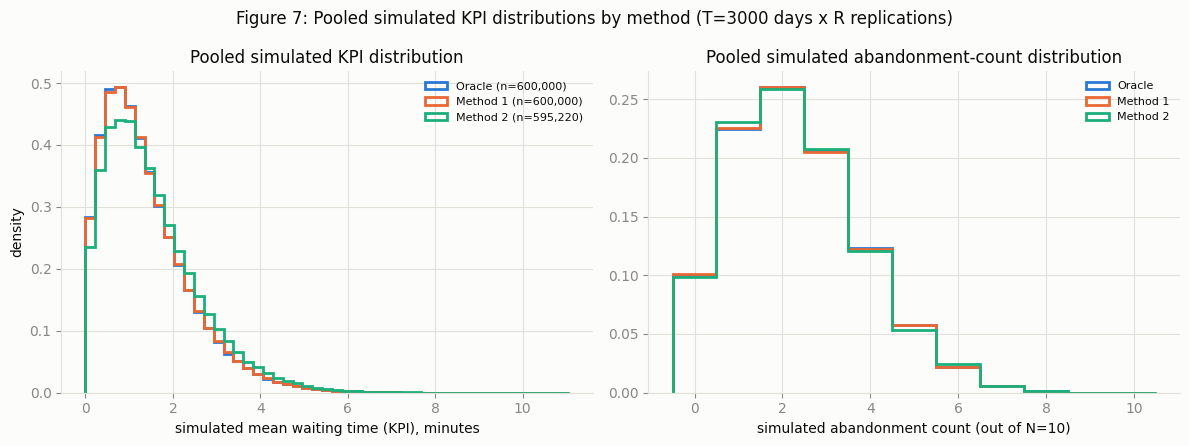

Oracle     KPI: mean=1.388  sd=1.014   abandon count: mean=2.325  sd=1.510  n=600,000
Method 1   KPI: mean=1.393  sd=1.015   abandon count: mean=2.318  sd=1.508  n=600,000
Method 2   KPI: mean=1.528  sd=1.080   abandon count: mean=2.318  sd=1.512  n=595,220


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

kpi_bins = np.linspace(
    min(pooled_samples[m]["kpi"].min() for m in METHODS),
    max(pooled_samples[m]["kpi"].max() for m in METHODS),
    50,
)
for method in METHODS:
    axes[0].hist(pooled_samples[method]["kpi"], bins=kpi_bins, density=True, histtype="step",
                 linewidth=2, color=METHOD_COLORS[method], label=f"{method} (n={len(pooled_samples[method]['kpi']):,})")
axes[0].set_xlabel("simulated mean waiting time (KPI), minutes")
axes[0].set_ylabel("density")
axes[0].set_title("Pooled simulated KPI distribution")
axes[0].legend(frameon=False, fontsize=8)

bins_ab = np.arange(-0.5, CFG.N + 1.5, 1)
for method in METHODS:
    axes[1].hist(pooled_samples[method]["abandon_count"], bins=bins_ab, density=True, histtype="step",
                 linewidth=2, color=METHOD_COLORS[method], label=method)
axes[1].set_xlabel(f"simulated abandonment count (out of N={CFG.N})")
axes[1].set_title("Pooled simulated abandonment-count distribution")
axes[1].legend(frameon=False, fontsize=8)

fig.suptitle(f"Figure 7: Pooled simulated KPI distributions by method (T={CFG.T} days x R replications)")
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "figure7_simulated_kpi_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()

for method in METHODS:
    kpi = pooled_samples[method]["kpi"]
    ab = pooled_samples[method]["abandon_count"]
    print(f"{method:9s}  KPI: mean={kpi.mean():.3f}  sd={kpi.std(ddof=1):.3f}   "
          f"abandon count: mean={ab.mean():.3f}  sd={ab.std(ddof=1):.3f}  n={len(kpi):,}")